In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers

(X_train, y_train), (X_test, y_test) = (
    keras.datasets.fashion_mnist.load_data()
)

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 13us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 33s 1us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 5s 1us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


In [2]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

In [3]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (60000, 28, 28, 1)
Testing shape: (10000, 28, 28, 1)


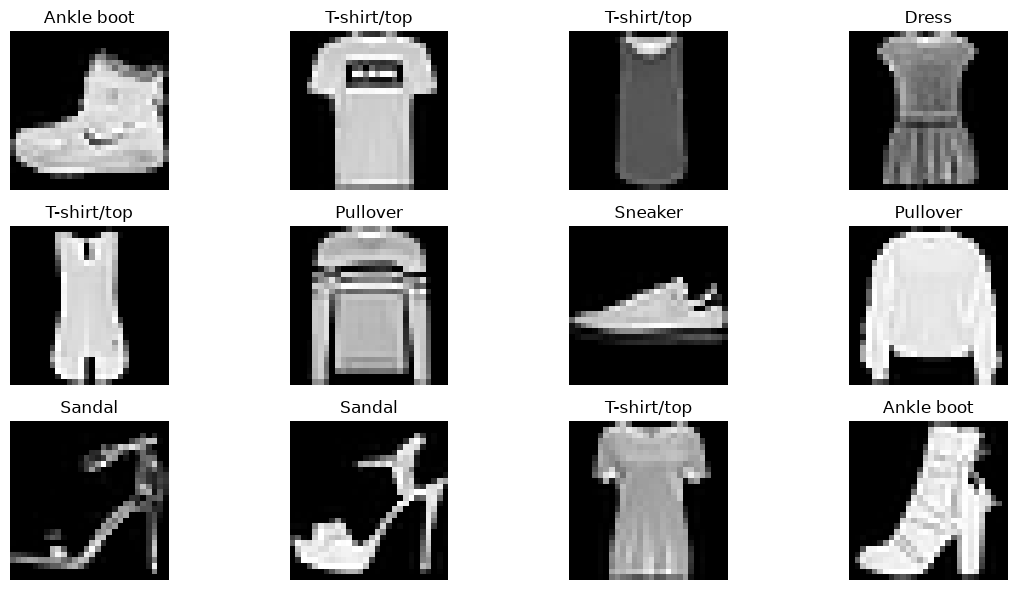

In [4]:
plt.figure(figsize=(12, 6))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_train[i].squeeze(), cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [5]:
cnn_model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # First convolution block
    layers.Conv2D(
        32,
        kernel_size=(3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Second convolution block
    layers.Conv2D(
        64,
        kernel_size=(3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Classification block
    layers.Flatten(),

    layers.Dropout(0.3),

    layers.Dense(128, activation="relu"),

    layers.Dense(10, activation="softmax")
])

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [7]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = cnn_model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=15,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.8059 - loss: 0.5354 - val_accuracy: 0.8604 - val_loss: 0.3912
Epoch 2/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.8671 - loss: 0.3661 - val_accuracy: 0.8769 - val_loss: 0.3350
Epoch 3/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.8840 - loss: 0.3159 - val_accuracy: 0.8936 - val_loss: 0.2956
Epoch 4/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.8961 - loss: 0.2839 - val_accuracy: 0.9022 - val_loss: 0.2717
Epoch 5/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.9039 - loss: 0.2584 - val_accuracy: 0.9012 - val_loss: 0.2667
Epoch 6/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.9118 - loss: 0.2399 - val_accuracy: 0.9006 - val_loss: 0.2685
Epoch 7/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.9162 - loss: 0.2235 - val_accuracy: 0.9112 - val_loss: 0.2453
Epoch 8/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.9206 - loss: 0.2120 - 

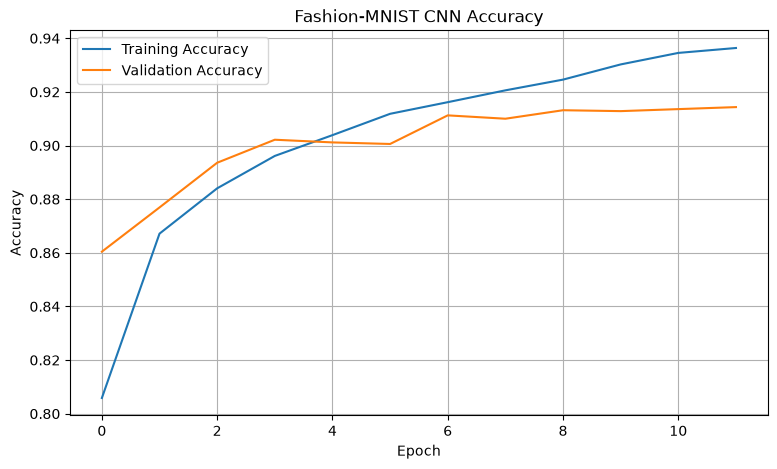

In [8]:
plt.figure(figsize=(9, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Fashion-MNIST CNN Accuracy")
plt.legend()
plt.grid(True)
plt.show()

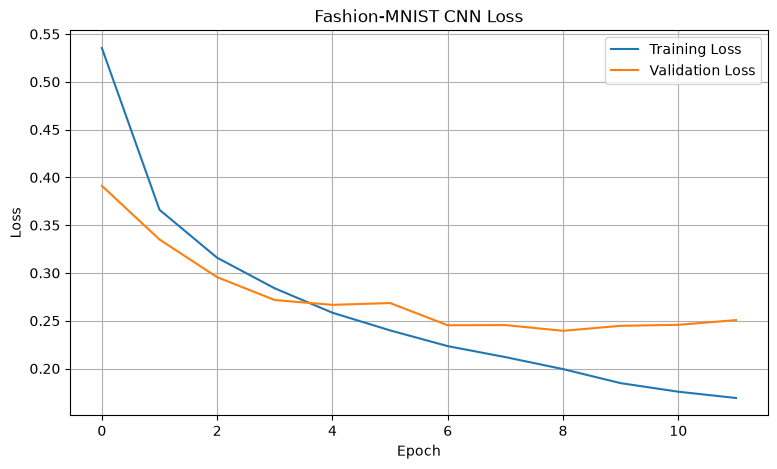

In [9]:
plt.figure(figsize=(9, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Fashion-MNIST CNN Loss")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
test_loss, test_accuracy = cnn_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 0.25733286142349243
Test Accuracy: 0.9068999886512756


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


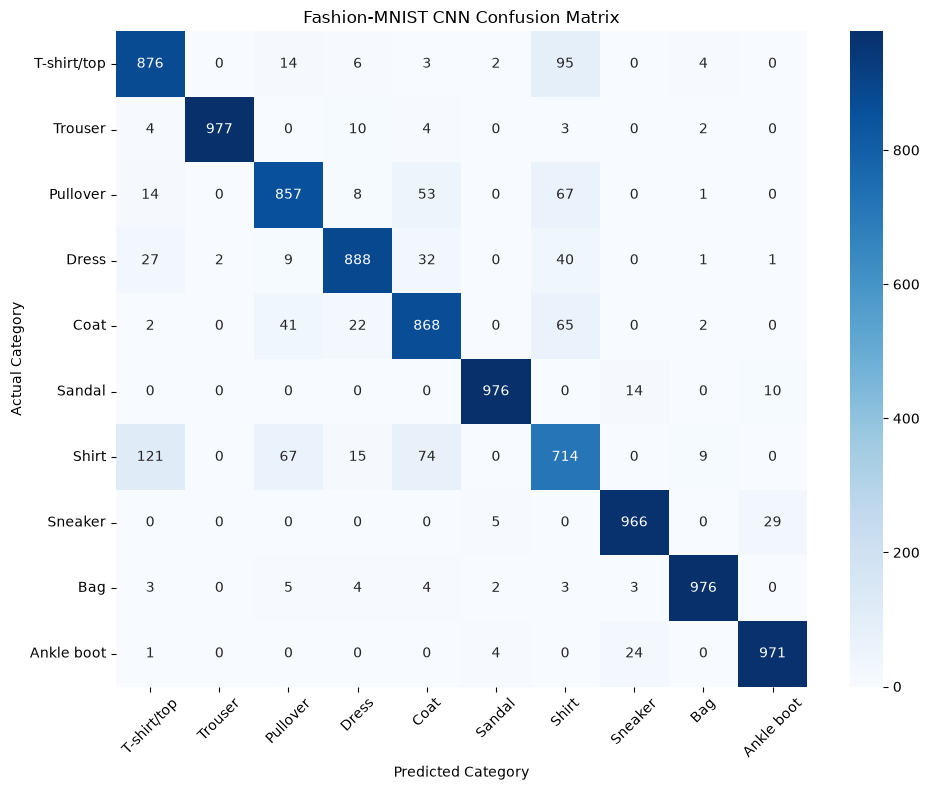

In [11]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

predictions = cnn_model.predict(X_test)

y_pred = np.argmax(predictions, axis=1)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Fashion-MNIST CNN Confusion Matrix")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [12]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

 T-shirt/top       0.84      0.88      0.86      1000
     Trouser       1.00      0.98      0.99      1000
    Pullover       0.86      0.86      0.86      1000
       Dress       0.93      0.89      0.91      1000
        Coat       0.84      0.87      0.85      1000
      Sandal       0.99      0.98      0.98      1000
       Shirt       0.72      0.71      0.72      1000
     Sneaker       0.96      0.97      0.96      1000
         Bag       0.98      0.98      0.98      1000
  Ankle boot       0.96      0.97      0.97      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



In [13]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("paramaggarwal/fashion-product-images-small")

print("Path to dataset files:", path)

ModuleNotFoundError: No module named 'kagglehub'

In [14]:
pip install kagglehub


   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kaggl

In [15]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("paramaggarwal/fashion-product-images-small")

print("Path to dataset files:", path)

100%|██████████| 565M/565M [03:59<00:00, 2.47MB/s] 

Extracting files...


Path to dataset files: C:\Users\SUBHOJIT\.cache\kagglehub\datasets\paramaggarwal\fashion-product-images-small\versions\1


In [16]:
from pathlib import Path

DATASET_PATH = Path(path)

csv_files = list(DATASET_PATH.rglob("styles.csv"))

if not csv_files:
    raise FileNotFoundError("styles.csv not found in downloaded dataset")

STYLES_PATH = csv_files[0]
IMAGE_DIR = STYLES_PATH.parent / "images"

print("Dataset directory:", DATASET_PATH)
print("Metadata file:", STYLES_PATH)
print("Image directory:", IMAGE_DIR)

print("Images directory exists:", IMAGE_DIR.exists())

Dataset directory: C:\Users\SUBHOJIT\.cache\kagglehub\datasets\paramaggarwal\fashion-product-images-small\versions\1
Metadata file: C:\Users\SUBHOJIT\.cache\kagglehub\datasets\paramaggarwal\fashion-product-images-small\versions\1\styles.csv
Image directory: C:\Users\SUBHOJIT\.cache\kagglehub\datasets\paramaggarwal\fashion-product-images-small\versions\1\images
Images directory exists: True


In [17]:
import pandas as pd

styles_df = pd.read_csv(
    STYLES_PATH,
    on_bad_lines="skip"
)

print("Dataset shape:", styles_df.shape)

styles_df.head()

Dataset shape: (44424, 10)


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt


In [18]:
print("Total image files:", len(list(IMAGE_DIR.glob("*.jpg"))))

print("Sample image files:")

for image_file in list(IMAGE_DIR.glob("*.jpg"))[:5]:
    print(image_file.name)

Total image files: 44441
Sample image files:
10000.jpg
10001.jpg
10002.jpg
10003.jpg
10004.jpg


In [19]:
styles_df["image_path"] = styles_df["id"].apply(
    lambda x: IMAGE_DIR / f"{int(x)}.jpg"
)

styles_df = styles_df.dropna(
    subset=["articleType"]
).copy()

styles_df = styles_df[
    styles_df["image_path"].apply(lambda x: x.exists())
].copy()

print("Available product images:", len(styles_df))

Available product images: 44419


In [20]:
category_counts = styles_df["articleType"].value_counts()

print("Total categories:", len(category_counts))

category_counts.head(20)

Total categories: 142


articleType
Tshirts                  7066
Shirts                   3215
Casual Shoes             2845
Watches                  2542
Sports Shoes             2036
Kurtas                   1844
Tops                     1762
Handbags                 1759
Heels                    1323
Sunglasses               1073
Wallets                   936
Flip Flops                914
Sandals                   897
Briefs                    849
Belts                     813
Backpacks                 724
Socks                     686
Formal Shoes              637
Perfume and Body Mist     613
Jeans                     608
Name: count, dtype: int64

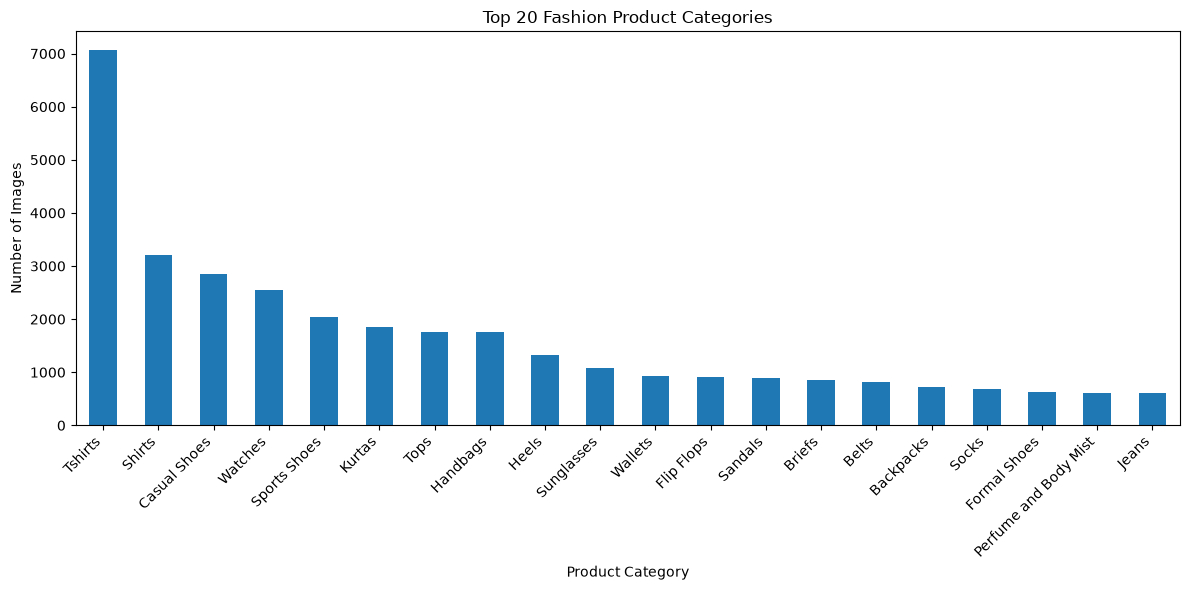

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

category_counts.head(20).plot(kind="bar")

plt.title("Top 20 Fashion Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [22]:
MIN_SAMPLES = 100

valid_categories = category_counts[
    category_counts >= MIN_SAMPLES
].index

product_df = styles_df[
    styles_df["articleType"].isin(valid_categories)
].copy()

print("Total product images:", len(product_df))
print("Selected categories:", product_df["articleType"].nunique())

Total product images: 42150
Selected categories: 54


In [23]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

product_df["label"] = label_encoder.fit_transform(
    product_df["articleType"]
)

class_names = label_encoder.classes_

print("Number of classes:", len(class_names))
print("\nCategory mapping:")

for index, category in enumerate(class_names):
    print(index, ":", category)

Number of classes: 54

Category mapping:
0 : Backpacks
1 : Belts
2 : Bra
3 : Briefs
4 : Capris
5 : Caps
6 : Casual Shoes
7 : Clutches
8 : Cufflinks
9 : Deodorant
10 : Dresses
11 : Dupatta
12 : Earrings
13 : Flats
14 : Flip Flops
15 : Formal Shoes
16 : Handbags
17 : Heels
18 : Innerwear Vests
19 : Jackets
20 : Jeans
21 : Kajal and Eyeliner
22 : Kurtas
23 : Kurtis
24 : Leggings
25 : Lip Gloss
26 : Lipstick
27 : Nail Polish
28 : Necklace and Chains
29 : Night suits
30 : Nightdress
31 : Pendant
32 : Perfume and Body Mist
33 : Ring
34 : Sandals
35 : Sarees
36 : Scarves
37 : Shirts
38 : Shorts
39 : Skirts
40 : Socks
41 : Sports Shoes
42 : Sunglasses
43 : Sweaters
44 : Sweatshirts
45 : Ties
46 : Tops
47 : Track Pants
48 : Trousers
49 : Trunk
50 : Tshirts
51 : Tunics
52 : Wallets
53 : Watches


In [24]:

from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    product_df,
    test_size=0.30,
    random_state=42,
    stratify=product_df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Testing records:", len(test_df))

Training records: 29505
Validation records: 6322
Testing records: 6323


In [25]:
print("Training distribution:")
print(train_df["label"].value_counts().sort_index())

print("\nValidation distribution:")
print(val_df["label"].value_counts().sort_index())

print("\nTesting distribution:")
print(test_df["label"].value_counts().sort_index())

Training distribution:
label
0      507
1      569
2      334
3      594
4      122
5      198
6     1992
7      203
8       74
9      243
10     325
11      81
12     291
13     350
14     640
15     446
16    1231
17     926
18     169
19     181
20     426
21      71
22    1291
23     164
24     124
25     101
26     221
27     230
28     112
29      99
30     132
31     123
32     429
33      83
34     628
35     299
36      83
37    2251
38     383
39      90
40     480
41    1425
42     751
43     194
44     200
45     184
46    1233
47     213
48     371
49      98
50    4946
51     160
52     655
53    1779
Name: count, dtype: int64

Validation distribution:
label
0      108
1      122
2       71
3      127
4       27
5       43
6      426
7       44
8       16
9       52
10      69
11      18
12      62
13      75
14     137
15      95
16     264
17     198
18      37
19      39
20      91
21      16
22     276
23      35
24      27
25      22
26      47
27      49
28      24


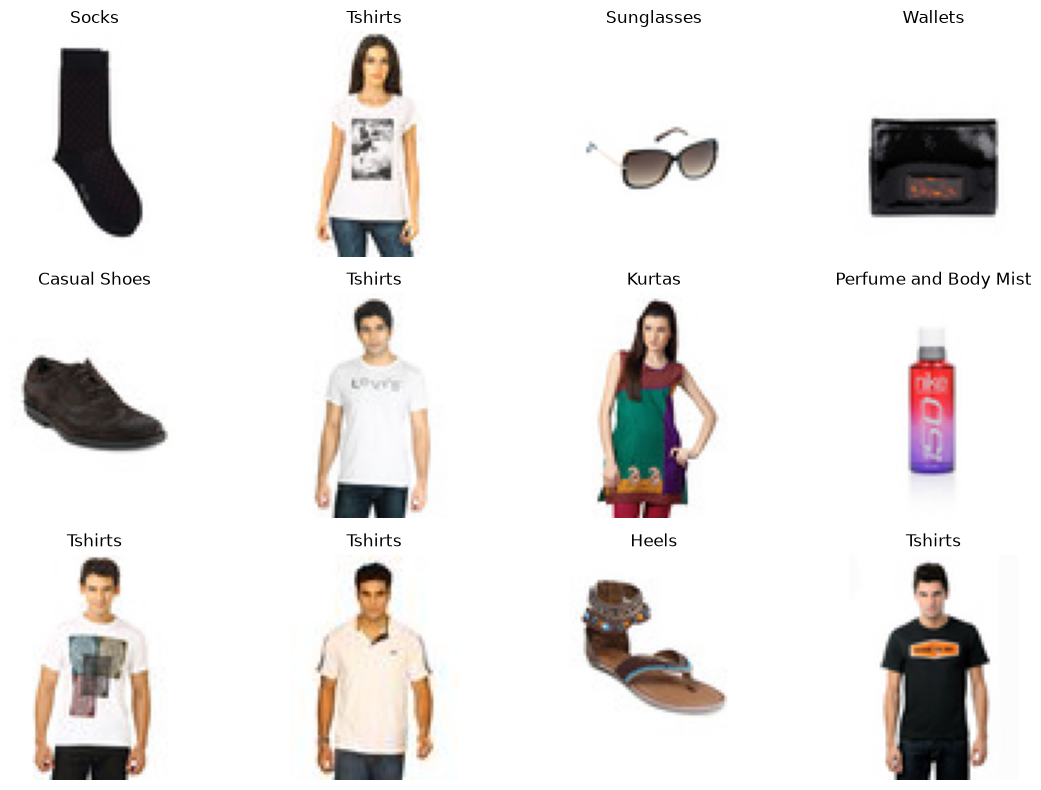

In [26]:
from PIL import Image

plt.figure(figsize=(12, 8))

sample_df = train_df.sample(
    n=12,
    random_state=42
).reset_index(drop=True)

for i, row in sample_df.iterrows():
    image = Image.open(row["image_path"]).convert("RGB")

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(row["articleType"])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [27]:
IMG_HEIGHT = 128
IMG_WIDTH = 128
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

NUM_CLASSES = len(class_names)

print("Image size:", IMG_HEIGHT, IMG_WIDTH)
print("Batch size:", BATCH_SIZE)
print("Number of classes:", NUM_CLASSES)

Image size: 128 128
Batch size: 32
Number of classes: 54


In [28]:
def load_and_preprocess_image(image_path, label):

    image = tf.io.read_file(image_path)

    image = tf.io.decode_jpeg(
        image,
        channels=3
    )

    image = tf.image.resize(
        image,
        [IMG_HEIGHT, IMG_WIDTH]
    )

    image = tf.cast(image, tf.float32) / 255.0

    return image, label

In [29]:
def create_image_dataset(dataframe, training=False):

    image_paths = dataframe["image_path"].astype(str).values
    labels = dataframe["label"].values.astype(np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=min(len(dataframe), 5000),
            seed=42
        )

    dataset = dataset.map(
        load_and_preprocess_image,
        num_parallel_calls=AUTOTUNE
    )

    if training:
        dataset = dataset.map(
            lambda image, label: (
                tf.image.random_flip_left_right(image),
                label
            ),
            num_parallel_calls=AUTOTUNE
        )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset

In [30]:
train_ds = create_image_dataset(
    train_df,
    training=True
)

val_ds = create_image_dataset(
    val_df,
    training=False
)

test_ds = create_image_dataset(
    test_df,
    training=False
)

In [31]:
for images, labels in train_ds.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)

    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image batch shape: (32, 128, 128, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


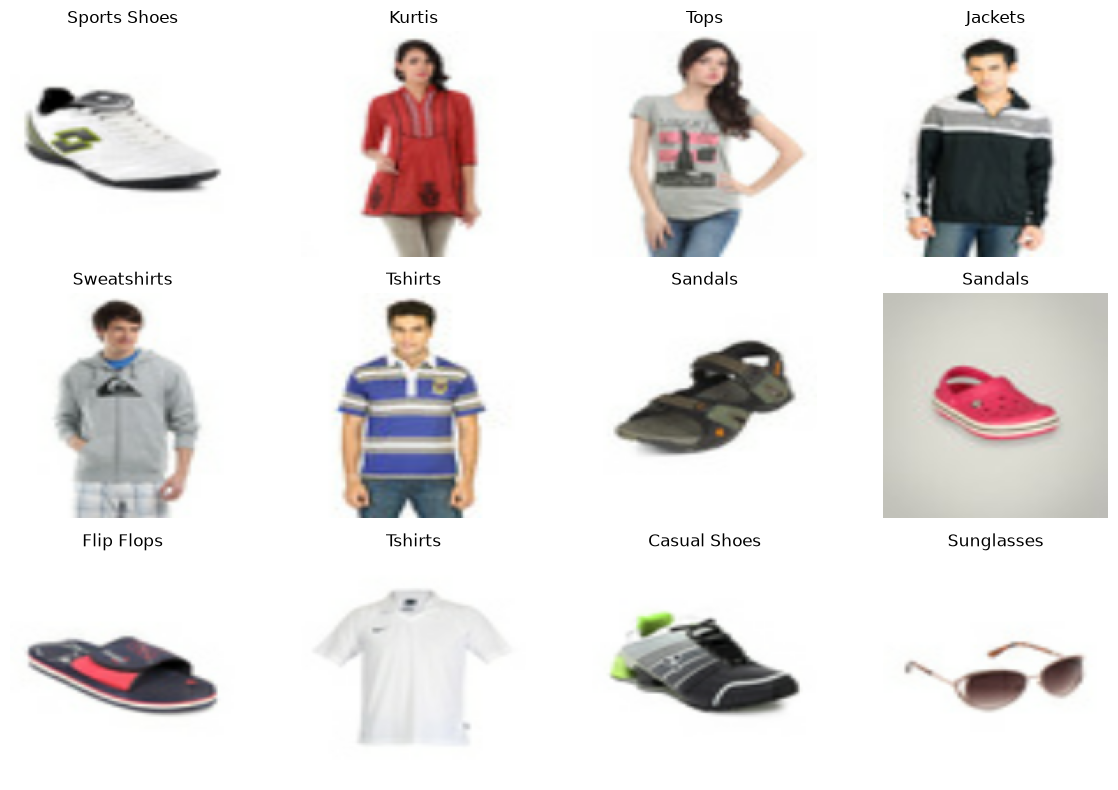

In [32]:
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):

    for i in range(min(12, len(images))):

        plt.subplot(3, 4, i + 1)

        plt.imshow(images[i].numpy())

        plt.title(class_names[labels[i].numpy()])

        plt.axis("off")

plt.tight_layout()
plt.show()

In [33]:
cnn_model = keras.Sequential([

    layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),

    # Convolution block 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 3
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Classification block
    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(NUM_CLASSES, activation="softmax")
])

cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 54)             │         6,966 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 116,726 (455.96 KB)

 Trainable params: 116,726 (455.96 KB)

 Non-trainable params: 0 (0.00 B)

In [34]:
cnn_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN compiled successfully.")

CNN compiled successfully.


In [36]:
from pathlib import Path

BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

print("Project directory:", BASE_DIR)

Project directory: d:\RetailMind


In [38]:
MODEL_DIR = BASE_DIR / "models"

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Model directory:", MODEL_DIR)

Model directory: d:\RetailMind\models


In [39]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ModelCheckpoint(
        filepath=str(
            MODEL_DIR / "best_product_cnn.keras"
        ),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

In [40]:
import numpy as np

# Actual labels
y_true = np.concatenate([
    labels.numpy()
    for _, labels in test_ds
])

# Predicted probabilities
y_prob = cnn_model.predict(test_ds)

# Convert probabilities into predicted class indices
y_pred = np.argmax(y_prob, axis=1)

print("Actual labels shape:", y_true.shape)
print("Predicted labels shape:", y_pred.shape)

198/198 ━━━━━━━━━━━━━━━━━━━━ 14s 71ms/step
Actual labels shape: (6323,)
Predicted labels shape: (6323,)


In [41]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Accuracy:", accuracy_score(y_true, y_pred))
print("Precision (weighted):", precision_score(y_true, y_pred, average="weighted", zero_division=0))
print("Recall (weighted):", recall_score(y_true, y_pred, average="weighted", zero_division=0))
print("F1 Score (weighted):", f1_score(y_true, y_pred, average="weighted", zero_division=0))

print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

Accuracy: 0.00537719436976119
Precision (weighted): 4.6618162657222354e-05
Recall (weighted): 0.00537719436976119
F1 Score (weighted): 9.03569664256701e-05

Classification Report:

                       precision    recall  f1-score   support

            Backpacks       0.00      0.00      0.00       109
                Belts       0.00      0.00      0.00       122
                  Bra       0.00      0.00      0.00        72
               Briefs       0.00      0.00      0.00       128
               Capris       0.00      0.00      0.00        26
                 Caps       0.00      0.00      0.00        42
         Casual Shoes       0.00      0.00      0.00       427
             Clutches       0.00      0.00      0.00        43
            Cufflinks       0.00      0.00      0.00        16
            Deodorant       0.00      0.00      0.00        52
              Dresses       0.00      0.00      0.00        70
              Dupatta       0.00      0.00      0.00        17

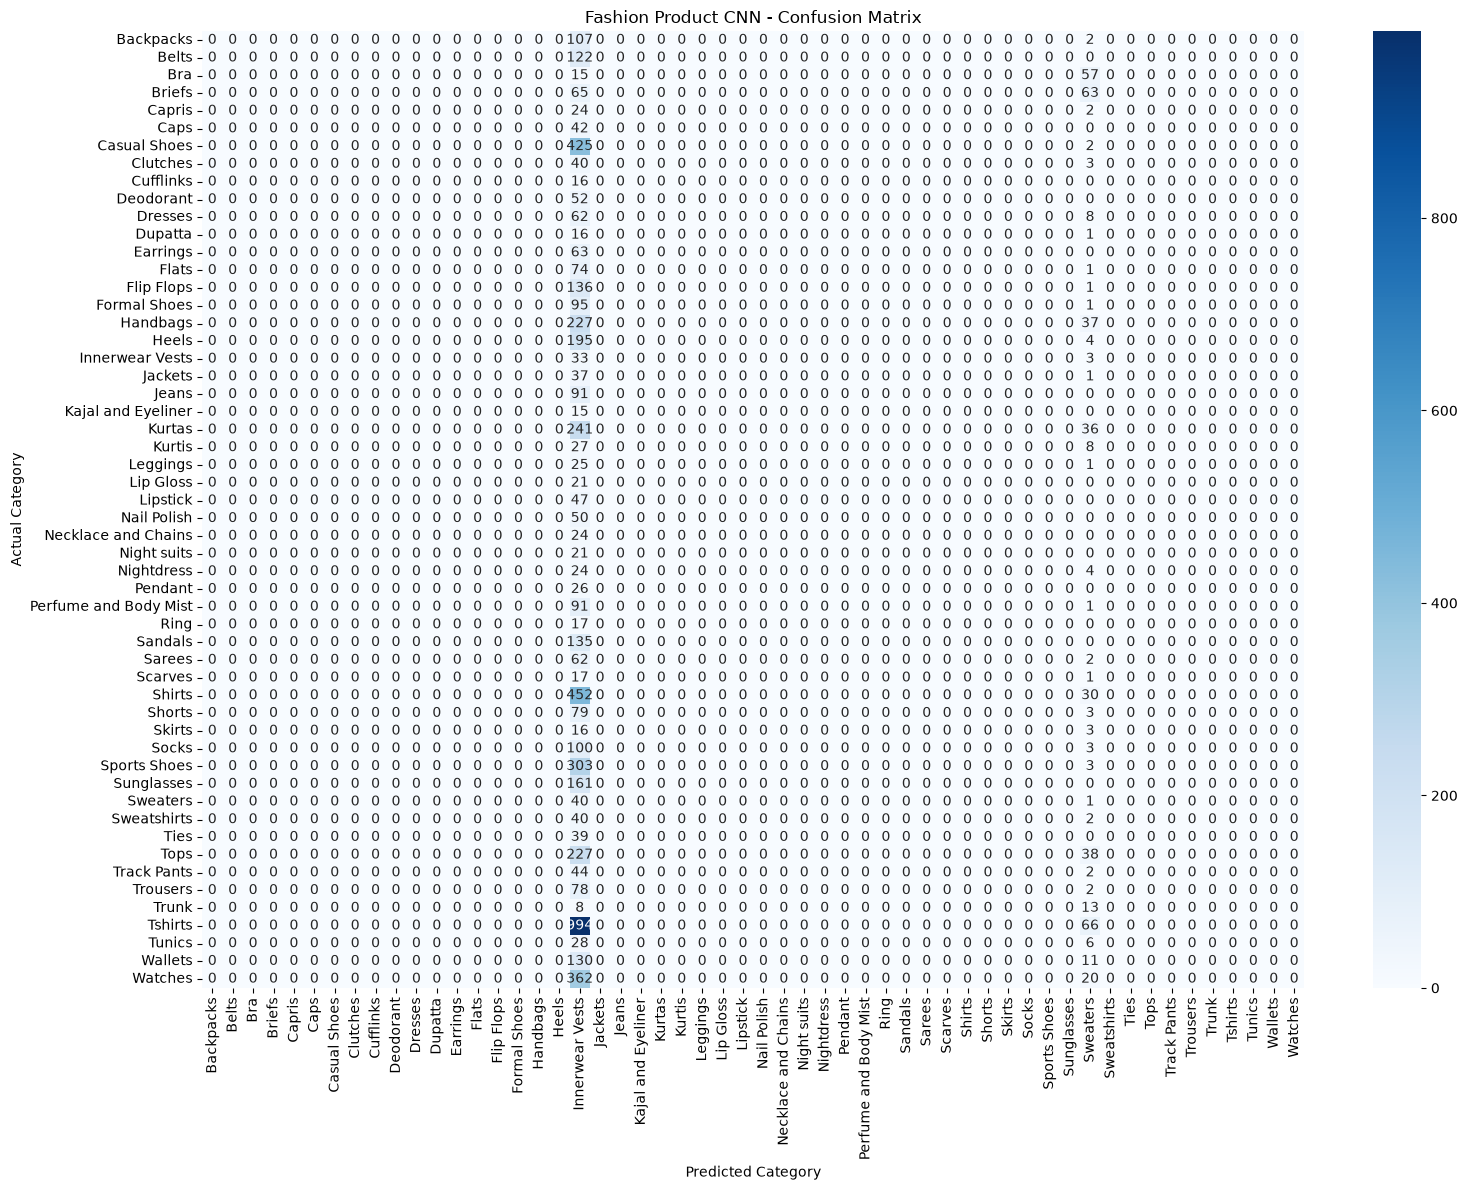

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(16, 12))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Fashion Product CNN - Confusion Matrix")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [43]:
def predict_product_image(image_path):
    image = tf.io.read_file(str(image_path))

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(
        image,
        [IMG_HEIGHT, IMG_WIDTH]
    )

    image = tf.cast(image, tf.float32) / 255.0

    # Add batch dimension
    image = tf.expand_dims(image, axis=0)

    # Predict probabilities
    probabilities = cnn_model.predict(image, verbose=0)[0]

    predicted_index = int(np.argmax(probabilities))

    predicted_category = class_names[predicted_index]

    confidence = float(probabilities[predicted_index]) * 100

    return predicted_category, confidence, probabilities

In [44]:
sample_image_path = test_df.iloc[0]["image_path"]

predicted_category, confidence, probabilities = predict_product_image(
    sample_image_path
)

print("Predicted category:", predicted_category)
print(f"Confidence: {confidence:.2f}%")

Predicted category: Innerwear Vests
Confidence: 2.08%


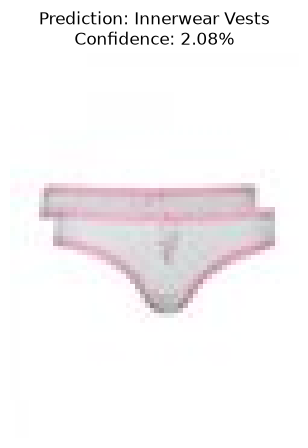

In [45]:
from PIL import Image
import matplotlib.pyplot as plt

image = Image.open(sample_image_path)

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.axis("off")

plt.title(
    f"Prediction: {predicted_category}\n"
    f"Confidence: {confidence:.2f}%"
)

plt.show()

In [46]:
top_3_indices = np.argsort(probabilities)[-3:][::-1]

for index in top_3_indices:
    print(
        f"{class_names[index]}: "
        f"{probabilities[index] * 100:.2f}%"
    )

Innerwear Vests: 2.08%
Sweaters: 2.08%
Jackets: 2.02%


In [47]:
import json

class_mapping = {
    int(index): str(category)
    for index, category in enumerate(class_names)
}

mapping_path = MODEL_DIR / "product_class_mapping.json"

with open(mapping_path, "w") as file:
    json.dump(class_mapping, file, indent=4)

print("Class mapping saved:", mapping_path)

Class mapping saved: d:\RetailMind\models\product_class_mapping.json


In [48]:
FINAL_MODEL_PATH = MODEL_DIR / "fashion_product_cnn.keras"

cnn_model.save(FINAL_MODEL_PATH)

print("Model saved at:", FINAL_MODEL_PATH)

Model saved at: d:\RetailMind\models\fashion_product_cnn.keras


In [49]:
image_config = {
    "image_height": IMG_HEIGHT,
    "image_width": IMG_WIDTH,
    "channels": 3,
    "normalization": "pixel_values_divided_by_255",
    "num_classes": int(NUM_CLASSES)
}

config_path = MODEL_DIR / "product_image_config.json"

with open(config_path, "w") as file:
    json.dump(image_config, file, indent=4)

print("Image configuration saved:", config_path)

Image configuration saved: d:\RetailMind\models\product_image_config.json


In [50]:

loaded_model = keras.models.load_model(
    MODEL_DIR / "fashion_product_cnn.keras"
)

print("Saved model loaded successfully!")

print("Input shape:", loaded_model.input_shape)
print("Output shape:", loaded_model.output_shape)

Saved model loaded successfully!
Input shape: (None, 128, 128, 3)
Output shape: (None, 54)


d:\RetailMind\.venv\Lib\site-packages\keras\src\saving\saving_lib.py:841: UserWarning: Skipping variable loading for optimizer 'adam_1', because it has 22 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)
